In [ ]:
### 지피티가 수정해준 코드
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, GaussianNoise
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.losses import CategoricalCrossentropy
from sklearn.metrics import classification_report
from collections import Counter
import math
import random

# ── 재현성(가능한 범위) ────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

# ── 경로/하이퍼파라미터 ──────────────────────────────────────────────
base_dir    = './PokemonData'   # 클래스별 하위 폴더 구조 필요
img_size    = (224, 224)
batch_size  = 32
epochs_head = 30                # 1단계(헤드) 최대 epoch
epochs_ft   = 50                # 2단계(미세튜닝) 최대 epoch
model_path  = 'best_pokemon_model.keras'

# ── 데이터 제너레이터 (훈련/검증 8:2) ─────────────────────────────────
# MobileNetV2 권장 전처리: preprocess_input ([-1,1] 스케일 등)
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
    rotation_range=25,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    shear_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)

val_generator = val_datagen.flow_from_directory(
    base_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# 클래스 맵/개수
class_indices = train_generator.class_indices
idx_to_class = [None] * len(class_indices)
for k, v in class_indices.items():
    idx_to_class[v] = k
num_classes = len(idx_to_class)
print(f"\n[INFO] 감지된 클래스 수: {num_classes} → {idx_to_class}")

# ── 클래스 불균형 보정(class_weight) ──────────────────────────────────
# train_generator.classes 는 학습분할의 각 샘플에 대한 정답 인덱스
train_labels = train_generator.classes
counts = Counter(train_labels)
max_count = max(counts.values())
class_weight = {cls_idx: max_count / cnt for cls_idx, cnt in counts.items()}
print("[INFO] class_weight:", class_weight)

# ── 사전학습 백본 + 커스텀 헤드 ──────────────────────────────────────
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # 1단계: 특성 추출 모드

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = GaussianNoise(0.05)(x)         # 미세한 노이즈로 일반화 ↑
x = Dense(256, activation='relu')(x)
x = Dropout(0.4)(x)                # 과적합 억제(조금 강화)
output = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

# ── 손실/옵티마이저/메트릭 ──────────────────────────────────────────
loss = CategoricalCrossentropy(label_smoothing=0.05)  # 라벨 스무딩
opt_head = tf.keras.optimizers.Adam(learning_rate=1e-3)

model.compile(optimizer=opt_head, loss=loss, metrics=['accuracy'])

# ── 콜백 (1단계) ─────────────────────────────────────────────────────
cb_common = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1, min_lr=1e-6),
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    ModelCheckpoint(model_path, monitor='val_accuracy', mode='max', save_best_only=True, verbose=1)
]

# ── 1단계 학습: 헤드만 학습 ──────────────────────────────────────────
print("\n[STAGE 1] 헤드 학습(백본 고정)")
history_head = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs_head,
    callbacks=cb_common,
    class_weight=class_weight,
    verbose=1
)

# ── 2단계: 상단 몇 개 블록만 풀어서 미세튜닝 ─────────────────────────
# MobileNetV2는 레이어 이름에 'block_XX' 구조. 상단(고수준 특징) 위주로 일부만 풀기.
# 너무 많이 풀면 불안정. 보통 마지막 20~40개 레이어 추천(환경 따라 조절).
fine_tune_at = 100  # 이 인덱스 이후 레이어를 풀어줌(대략 모델 상단부)
for i, layer in enumerate(base_model.layers):
    layer.trainable = (i >= fine_tune_at)

# 미세튜닝은 더 낮은 학습률과 가중감쇠(AdamW) 권장
opt_ft = tf.keras.optimizers.AdamW(learning_rate=3e-5, weight_decay=1e-4)
model.compile(optimizer=opt_ft, loss=loss, metrics=['accuracy'])

print("\n[STAGE 2] 상단 레이어 미세튜닝")
history_ft = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs_ft,
    callbacks=cb_common,
    class_weight=class_weight,
    verbose=1
)

# ── 최적 가중치 로드(체크포인트) ─────────────────────────────────────
if os.path.exists(model_path):
    model.load_weights(model_path)

# ── 평가/예측 및 리포트 ──────────────────────────────────────────────
val_generator.reset()
y_pred = model.predict(val_generator, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = val_generator.classes
class_labels = list(val_generator.class_indices.keys())

print("\n[CLASSIFICATION REPORT]")
print(classification_report(y_true, y_pred_classes, target_names=class_labels, digits=4))

# ── 저장(최종) ───────────────────────────────────────────────────────
model.save('pokemon_mobilenetv2_finetuned.keras')
print("\n[OK] 모델 저장 완료: pokemon_mobilenetv2_finetuned.keras")


Found 11945 images belonging to 151 classes.


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


374/374 ━━━━━━━━━━━━━━━━━━━━ 185s 491ms/step - accuracy: 0.9838 - loss: 0.6445

=== 최종 평가 결과 ===
Loss: 0.6445
Accuracy: (미정)


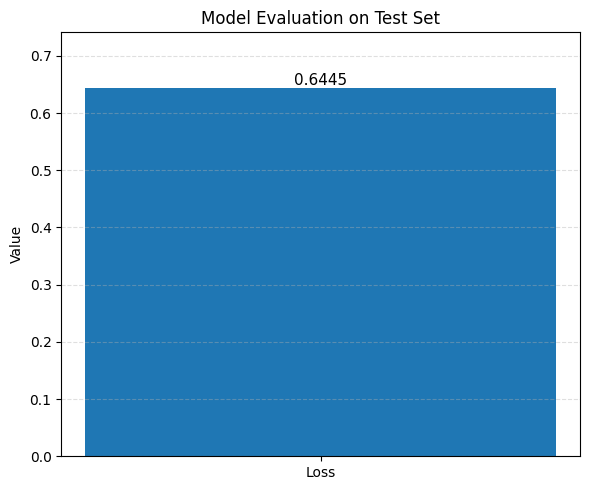

In [2]:
# -*- coding: utf-8 -*-
"""
목적:
- 저장된 Keras 모델(.keras/.h5)을 불러와 테스트셋으로 최종 loss/accuracy를 계산
- 결과를 막대 그래프로 시각화

전제:
- 테스트 데이터 폴더 구조: test_dir/클래스명/이미지파일들 ...
- (예) TestData/Pikachu/xxx.png , TestData/Bulbasaur/yyy.jpg
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# (MobileNetV2로 학습했다면)
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# ================== 사용자 설정 ==================
model_path = "pokemon_mobilenetv2_finetuned.keras"   # 저장된 모델 경로(.keras/.h5)
test_dir   = "PokemonData"                   # 테스트 데이터 루트 폴더
img_size   = (224, 224)                   # 학습 때 쓰던 입력 크기와 동일
batch_size = 32

# MobileNetV2 외 다른 전처리를 썼다면 아래처럼 교체:
# test_datagen = ImageDataGenerator(rescale=1.0/255.0)
# ===============================================

# 1) 모델 로드
model = load_model(model_path)

# 2) 출력 차원으로 binary/categorical 자동 판별
#    출력 shape 예: (None, 1) -> binary, (None, N) -> categorical
out_dim = model.outputs[0].shape[-1]
try:
    out_dim = int(out_dim)
except Exception:
    # 동적 shape일 때 대비
    out_dim = 1 if "sigmoid" in str(model.layers[-1].activation.__name__).lower() else None

if out_dim == 1:
    class_mode = "binary"
else:
    class_mode = "categorical"

# 3) 테스트 제너레이터 준비 (MobileNetV2 전처리)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode=class_mode,
    shuffle=False
)

# 4) 평가
results = model.evaluate(test_gen, verbose=1)
# 모델 compile 순서에 따라 metrics가 다를 수 있으니 키를 가져온다
metric_names = model.metrics_names  # 예: ['loss', 'accuracy'] 또는 ['loss', 'binary_accuracy'] 등

# loss/accuracy 값 꺼내기
loss_val = None
acc_val  = None

for name, val in zip(metric_names, results if isinstance(results, (list, tuple)) else [results]):
    if name == "loss":
        loss_val = float(val)
    if "acc" in name or "accuracy" in name:
        acc_val = float(val)

print("\n=== 최종 평가 결과 ===")
print(f"Loss: {loss_val:.4f}" if loss_val is not None else "Loss: (미정)")
print(f"Accuracy: {acc_val:.4f}" if acc_val is not None else "Accuracy: (미정)")

# 5) 시각화 (막대 그래프)
#    서로 스케일이 달라도 직관적으로 보이도록 두 지표를 나란히 표시
labels = []
values = []
if loss_val is not None:
    labels.append("Loss")
    values.append(loss_val)
if acc_val is not None:
    labels.append("Accuracy")
    values.append(acc_val)

plt.figure(figsize=(6, 5))
bars = plt.bar(labels, values)
plt.title("Model Evaluation on Test Set")
plt.ylabel("Value")

# 막대 위에 수치 표시
for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f"{v:.4f}", ha='center', va='bottom', fontsize=11)

plt.ylim(0, max(values) * 1.15 if values else 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


In [ ]:
print(classification_report(y_true, y_pred_classes, target_names=class_labels, digits=4))


In [ ]:

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import numpy as np
from sklearn.metrics import classification_report
import os

# ── 경로/하이퍼파라미터 ──────────────────────────────────────────────
base_dir   = './PokemonData'   # 클래스별 하위폴더 포함
img_size   = (224, 224)
batch_size = 32
epochs     = 300
num_classes = 3                         # 클래스 개수

# ── 데이터 제너레이터 (훈련/검증 8:2 분할) ─────────────────────────────
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = datagen.flow_from_directory(
    base_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',       # 학습용
    shuffle=True
)

val_generator = datagen.flow_from_directory(
    base_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',     # 검증용
    shuffle=False
)


# 클래스 정보
class_indices = train_generator.class_indices       # {'classA':0, ...}
idx_to_class = [None]*len(class_indices)
for k, v in class_indices.items():
    idx_to_class[v] = k
num_classes = len(idx_to_class)
print(f"\n[INFO] 감지된 클래스 수: {num_classes} → {idx_to_class}")




# ── 사전학습 모델(MobileNetV2) + 커스텀 분류기 ────────────────────────
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # 특성 추출 모드

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# ── 콜백 (EarlyStopping, 체크포인트) ──────────────────────────────────
early_stop  = EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss')
model_path  = 'best_animal_model.keras'
checkpoint  = ModelCheckpoint(model_path, save_best_only=True, monitor='val_loss')

# ── 학습 ───────────────────────────────────────────────────────────────
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs,
    callbacks=[early_stop, checkpoint]
)

# ── 평가/예측 및 리포트 ───────────────────────────────────────────────
val_generator.reset()
y_pred = model.predict(val_generator)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = val_generator.classes
class_labels = list(val_generator.class_indices.keys())

print(classification_report(y_true, y_pred_classes, target_names=class_labels))





In [ ]:
print(idx_to_class)

In [ ]:
### 여러 장의 이미지 예측 (폴더 형태)

import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image



# 1) 저장된 모델 불러오기
model_path = "best_animal_model.keras"  # 학습 완료 후 저장한 모델 경로
model = load_model(model_path)

# 2) 테스트 이미지 폴더
test_dir = "Test_File"  # 폴더 안에 포켓몬별 하위폴더로 이미지가 있어야 함
img_size = (224, 224)

# 3) 클래스 이름 불러오기 (train_generator.class_indices를 알고 있어야 함)
class_names = idx_to_class  # 실제 학습 때 순서대로

# 4) 테스트 데이터 수집
test_images = []
true_labels = []

for label in class_names:
    folder_path = os.path.join(test_dir, label)
    if os.path.exists(folder_path):
        for f in os.listdir(folder_path):
            if f.lower().endswith(('.png','.jpg','.jpeg','.bmp','.webp')):
                test_images.append(os.path.join(folder_path, f))
                true_labels.append(label)

# 5) 예측 + 시각화
plt.figure(figsize=(20, 15))
for i, img_path in enumerate(test_images):
    if i >= 16:  # 최대 16장만 표시
        break
    img = image.load_img(img_path, target_size=img_size)
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    
    preds = model.predict(img_array)
    pred_idx = np.argmax(preds[0])
    pred_label = class_names[pred_idx]
    true_label = true_labels[i]
    
    # 맞으면 초록, 틀리면 빨강
    title_color = 'green' if pred_label == true_label else 'red'
    
    plt.subplot(4, 4, i+1)
    plt.imshow(img)
    plt.title(f"실제: {true_label}\n예측: {pred_label}", color=title_color)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
### 한 장의 이미지 예측


import os, json, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ===== 설정 =====
MODEL_PATH = "best_animal_model.keras"   # 학습된 모델(.keras)
IMG_PATH   = "path/to/your_image.jpg"    # ← 예측할 이미지 경로
IMAGE_SIZE = (224, 224)                  # 학습과 동일
LABELS_PATH = "class_labels.json"        # (선택) 훈련 때 저장한 라벨 순서
BASE_DIR    = "Test_File"                # (백업) 라벨 복구용: 클래스별 하위폴더 구조

# 1) 모델 로드
model = load_model(MODEL_PATH)
out_dim = model.output_shape[-1]

# 2) 라벨(idx→class) 로드/복구
def load_labels():
    if os.path.isfile(LABELS_PATH):
        with open(LABELS_PATH, "r", encoding="utf-8") as f:
            labels = json.load(f)
        if len(labels) == out_dim:
            return labels
        else:
            print(f"[WARN] LABELS_PATH 라벨 수({len(labels)}) != 모델 출력({out_dim}), BASE_DIR로 복구 시도")
    if not os.path.isdir(BASE_DIR):
        raise FileNotFoundError(f"[ERROR] '{LABELS_PATH}'도 없고 BASE_DIR '{BASE_DIR}'도 없어 라벨을 복구할 수 없음.")
    gen = ImageDataGenerator(rescale=1./255).flow_from_directory(
        BASE_DIR, target_size=IMAGE_SIZE, batch_size=1, class_mode='categorical', shuffle=False
    )
    idx_to_class = [None]*len(gen.class_indices)
    for name, idx in gen.class_indices.items():
        idx_to_class[idx] = name
    if len(idx_to_class) != out_dim:
        raise ValueError(f"[ERROR] 라벨 수({len(idx_to_class)})와 모델 출력({out_dim}) 불일치.")
    return idx_to_class

idx_to_class = load_labels()
print("[INFO] classes:", idx_to_class)

# 3) 이미지 전처리(학습 때 rescale=1./255 사용)
if not os.path.isfile(IMG_PATH):
    raise FileNotFoundError(f"이미지 파일이 없습니다: {os.path.abspath(IMG_PATH)}")
img = image.load_img(IMG_PATH, target_size=IMAGE_SIZE)
x = image.img_to_array(img) / 255.0
x = np.expand_dims(x, axis=0)

# 4) 예측
probs = model.predict(x, verbose=0)[0]   # (num_classes,)
pred_idx = int(np.argmax(probs))
pred_label, pred_prob = idx_to_class[pred_idx], float(probs[pred_idx])

print(f"\n[Pred] {pred_label} ({pred_prob*100:.2f}%)")
TOP_K = min(5, len(idx_to_class))
order = probs.argsort()[::-1][:TOP_K]
print(f"[Top-{TOP_K}]")
for i in order:
    print(f"  {idx_to_class[i]}: {probs[i]*100:.2f}%")

# 5) 시각화
plt.figure(figsize=(5,5))
plt.imshow(image.load_img(IMG_PATH))
plt.axis('off')
plt.title(f"{pred_label} ({pred_prob*100:.1f}%)")
plt.show()
